# OULAD Milestone 3: Predictive modelling

**Research topic:** Machine Learning Based Prediction of Student Academic Performance in Open University Settings Using Online Engagement

This notebook uses the validated analytical datasets from the EDA notebook. It compares Logistic Regression, Random Forest and XGBoost at Weeks 2, 4 and 6. The main aim is to identify the earliest window that provides reliable classification of successful and adverse outcomes.

The results will support RQ2, which asks which prediction window is the earliest reliable point, and RQ3, which asks which engagement and assessment predictors are most strongly associated with final outcomes.

The model evaluation gives special attention to recall and F1 score for the adverse outcome group because failing to identify a student at risk would reduce the usefulness of an early intervention system.


## Modelling decisions

The same student population is used at Weeks 2, 4 and 6 so that differences in performance reflect the amount of information available at each window. Identifiers, the target, final outcome information and later withdrawal information are excluded to reduce data leakage.

Missing numerical values are replaced with the training median and missingness indicators are added. Categorical values are replaced with the most frequent training category and then one hot encoded. All transformations are placed inside the modelling pipeline so that information from the test data is not used during training.

The modelling results do not prove causation. They show how well the available early information classifies the final outcome.


In [1]:
# Load libraries

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    make_scorer
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [2]:
# Locate the prepared analytical datasets

candidate_folders = [
    Path.cwd() / "oulad_outputs",
    Path.cwd().parent / "oulad_outputs",
    Path("/content/oulad_outputs")
]

output_folder = next(
    (folder for folder in candidate_folders if folder.exists()),
    None
)

if output_folder is None:
    raise FileNotFoundError(
        "The oulad_outputs folder was not found. "
        "Place this notebook beside the preparation output folder."
    )

modelling_folder = output_folder / "modelling"
modelling_folder.mkdir(exist_ok=True)

window_files = {
    window: output_folder / f"oulad_analytical_week_{window}.csv"
    for window in [2, 4, 6]
}

missing_files = [
    str(path)
    for path in window_files.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"The following analytical files are missing: {missing_files}"
    )

analytical_datasets = {}

for window, path in window_files.items():
    data = pd.read_csv(path, low_memory=False)
    data.columns = data.columns.astype(str).str.strip()
    analytical_datasets[window] = data
    print(
        f"Week {window}: {data.shape[0]:,} rows and "
        f"{data.shape[1]} columns"
    )

print("All three analytical datasets loaded successfully.")


Week 2: 32,593 rows and 40 columns
Week 4: 32,593 rows and 42 columns
Week 6: 32,593 rows and 42 columns
All three analytical datasets loaded successfully.


In [3]:
# Check the target and the number of records

for window, data in analytical_datasets.items():
    print(f"\nWeek {window}")
    print("Rows:", len(data))
    print("Target values:", sorted(data["target"].dropna().unique()))
    print("Missing target values:", int(data["target"].isna().sum()))
    print("Duplicate rows:", int(data.duplicated().sum()))



Week 2
Rows: 32593
Target values: [np.int64(0), np.int64(1)]
Missing target values: 0
Duplicate rows: 0

Week 4
Rows: 32593
Target values: [np.int64(0), np.int64(1)]
Missing target values: 0
Duplicate rows: 0

Week 6
Rows: 32593
Target values: [np.int64(0), np.int64(1)]
Missing target values: 0
Duplicate rows: 0


In [4]:
# Define the columns and candidate predictors

student_key = [
    "id_student",
    "code_module",
    "code_presentation"
]

# These columns are not allowed to enter the models
excluded_columns = student_key + [
    "final_result",
    "target",
    "prediction_window_week",
    "date_unregistration"
]

numeric_candidates = [
    "total_clicks",
    "active_days",
    "unique_learning_sites",
    "interaction_records",
    "assessment_record_count",
    "scored_assessment_count",
    "submitted_assessment_count",
    "assessment_submission_rate",
    "assessment_score_mean",
    "avg_TMA_score",
    "avg_CMA_score",
    "num_of_prev_attempts",
    "studied_credits"
]

categorical_candidates = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

print("Excluded columns:", excluded_columns)
print("Candidate numerical features:", numeric_candidates)
print("Candidate categorical features:", categorical_candidates)


Excluded columns: ['id_student', 'code_module', 'code_presentation', 'final_result', 'target', 'prediction_window_week', 'date_unregistration']
Candidate numerical features: ['total_clicks', 'active_days', 'unique_learning_sites', 'interaction_records', 'assessment_record_count', 'scored_assessment_count', 'submitted_assessment_count', 'assessment_submission_rate', 'assessment_score_mean', 'avg_TMA_score', 'avg_CMA_score', 'num_of_prev_attempts', 'studied_credits']
Candidate categorical features: ['gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']


# Model definitions
### Preprocessing pipeline and model definitions

The next stage prepares the data for machine learning and defines the classification models used in the study. Numerical variables are processed using median imputation, missing-value indicators, and standardisation. Categorical variables are processed using most frequent-value imputation and one-hot encoding.

These preprocessing steps are combined with each machine learning algorithm in a single pipeline. This ensures that the data is prepared consistently before training and helps reduce the risk of data leakage.

Three models are defined for comparison: Logistic Regression, Random Forest, and XGBoost. Logistic Regression provides a baseline model, while Random Forest and XGBoost provide more complex tree-based approaches.


In [12]:
# Create a compatible one-hot encoder.
# Different versions of scikit-learn use different parameter names.
def make_one_hot_encoder():

    try:
        # Used in newer versions of scikit-learn
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:
        # Used in older versions of scikit-learn
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )


# Create a complete preprocessing and modelling pipeline
def create_pipeline(data, model):

    # Select numerical variables that are available
    # in the current dataset
    numeric_features = [
        column
        for column in numeric_candidates
        if column in data.columns
    ]

    # Select categorical variables that are available
    # in the current dataset
    categorical_features = [
        column
        for column in categorical_candidates
        if column in data.columns
    ]

    # Preprocessing steps for numerical variables
    numeric_pipeline = Pipeline(steps=[

        # Replace missing numerical values with
        # the median value of each variable
        (
            "imputer",
            SimpleImputer(
                strategy="median",

                # Create an extra indicator showing
                # where values were originally missing
                add_indicator=True
            )
        ),

        # Standardise the numerical variables so they
        # are placed on comparable scales
        ("scaler", StandardScaler())
    ])

    # Preprocessing steps for categorical variables
    categorical_pipeline = Pipeline(steps=[

        # Replace missing categorical values with
        # the most common category
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        # Convert categorical values into numerical
        # one-hot encoded columns
        ("one_hot_encoder", make_one_hot_encoder())
    ])

    # Apply the numerical pipeline to numerical variables
    # and the categorical pipeline to categorical variables
    preprocessor = ColumnTransformer(
        transformers=[

            (
                "numeric",
                numeric_pipeline,
                numeric_features
            ),

            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        ],

        # Ignore columns that were not included in either
        # the numerical or categorical feature lists
        remainder="drop"
    )

    # Combine preprocessing and the selected model
    # into one complete pipeline
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])


### Defining the modles


In [13]:
# Define the machine learning models that will be compared
models = {

    # Logistic Regression is used as a baseline model.
    # It provides a simple reference point for comparison.
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    # Random Forest combines the predictions of many
    # decision trees.
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    # XGBoost builds trees sequentially, with each new tree
    # attempting to improve previous predictions.
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Display the names of the models that have been created
print("Models defined:", list(models.keys()))


Models defined: ['Logistic Regression', 'Random Forest', 'XGBoost']


The output confirms that the three planned classification models were defined successfully. At this stage, the models have not yet been trained or evaluated. The next step is to fit each complete pipeline to the training data and compare their predictions using the selected evaluation metrics.


In [6]:
# Define the evaluation metrics

# Class 0 is the adverse outcome and class 1 is the successful outcome
adverse_precision = make_scorer(
    precision_score,
    pos_label=0,
    zero_division=0
)

adverse_recall = make_scorer(
    recall_score,
    pos_label=0,
    zero_division=0
)

adverse_f1 = make_scorer(
    f1_score,
    pos_label=0,
    zero_division=0
)

scoring = {
    "accuracy": "accuracy",
    "adverse_precision": adverse_precision,
    "adverse_recall": adverse_recall,
    "adverse_f1": adverse_f1,
    "roc_auc": "roc_auc"
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Evaluation metrics defined.")


Evaluation metrics defined.


## Model training and comparison

The data is split into training and test sets using stratification. Stratification keeps the proportion of successful and adverse outcomes similar in both sets. The cross validation results provide a more reliable estimate than one split alone.

The adverse outcome recall is especially important. A high adverse outcome recall means that the model identifies a large proportion of students who eventually experience an adverse outcome. The adverse outcome F1 score balances this recall with precision.


In [7]:
# Train and evaluate every model at every prediction window

results = []
confusion_rows = []
fitted_pipelines = {}

for window, data in analytical_datasets.items():

    # Remove records without a target
    modelling_data = data.dropna(subset=["target"]).copy()

    # Keep only permitted predictors
    predictor_columns = [
        column
        for column in modelling_data.columns
        if column not in excluded_columns
        and (
            column in numeric_candidates
            or column in categorical_candidates
        )
    ]

    X = modelling_data[predictor_columns]
    y = modelling_data["target"].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=42
    )

    for model_name, model in models.items():

        pipeline = create_pipeline(
            modelling_data,
            model
        )

        # Fit the complete pipeline on the training data
        pipeline.fit(X_train, y_train)

        # Generate test predictions
        y_pred = pipeline.predict(X_test)
        y_probability = pipeline.predict_proba(X_test)[:, 1]

        # Calculate test set results
        test_result = {
            "window": f"Week {window}",
            "model": model_name,
            "accuracy": accuracy_score(y_test, y_pred),
            "adverse_precision": precision_score(
                y_test,
                y_pred,
                pos_label=0,
                zero_division=0
            ),
            "adverse_recall": recall_score(
                y_test,
                y_pred,
                pos_label=0,
                zero_division=0
            ),
            "adverse_f1": f1_score(
                y_test,
                y_pred,
                pos_label=0,
                zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_test,
                y_probability
            )
        }

        # Calculate five fold cross validation results
        cv_result = cross_validate(
            pipeline,
            X,
            y,
            cv=cv_strategy,
            scoring=scoring,
            n_jobs=1
        )

        for metric_name in scoring:
            test_result[f"cv_{metric_name}_mean"] = cv_result[
                f"test_{metric_name}"
            ].mean()
            test_result[f"cv_{metric_name}_std"] = cv_result[
                f"test_{metric_name}"
            ].std()

        results.append(test_result)

        # Store the confusion matrix values
        matrix = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1]
        )

        confusion_rows.append({
            "window": f"Week {window}",
            "model": model_name,
            "true_adverse_predicted_adverse": int(matrix[0, 0]),
            "true_adverse_predicted_successful": int(matrix[0, 1]),
            "true_successful_predicted_adverse": int(matrix[1, 0]),
            "true_successful_predicted_successful": int(matrix[1, 1])
        })

        fitted_pipelines[(window, model_name)] = (
            pipeline,
            predictor_columns
        )

        print(
            f"Completed {model_name} for Week {window}. "
            f"Adverse recall: {test_result['adverse_recall']:.3f}"
        )

results_df = pd.DataFrame(results)
confusion_df = pd.DataFrame(confusion_rows)

print("All models have been trained and evaluated.")


Completed Logistic Regression for Week 2. Adverse recall: 0.631
Completed Random Forest for Week 2. Adverse recall: 0.613
Completed XGBoost for Week 2. Adverse recall: 0.695
Completed Logistic Regression for Week 4. Adverse recall: 0.681
Completed Random Forest for Week 4. Adverse recall: 0.672
Completed XGBoost for Week 4. Adverse recall: 0.696
Completed Logistic Regression for Week 6. Adverse recall: 0.674
Completed Random Forest for Week 6. Adverse recall: 0.689
Completed XGBoost for Week 6. Adverse recall: 0.696
All models have been trained and evaluated.


### Initial model evaluation interpretation

All nine model experiments were completed successfully. Three classification models were trained and evaluated at each prediction point: Week 2, Week 4, and Week 6.

The output reports adverse recall, which measures the proportion of students who experienced the adverse outcome and were correctly identified by each model. Higher recall is important because it indicates that the model is better at detecting students who may require early academic support.

XGBoost achieved the highest adverse recall at all three prediction points. Its recall was 69.5% at Week 2 and 69.6% at both Week 4 and Week 6. This indicates that XGBoost provided the most consistent performance for identifying students with an adverse outcome.

Random Forest showed the greatest improvement over time, increasing from 61.3% at Week 2 to 68.9% at Week 6. Logistic Regression also improved between Week 2 and Week 4, but its recall decreased slightly at Week 6.

These results provide an initial indication that XGBoost may be the strongest model for detecting adverse outcomes. However, adverse recall represents only one aspect of model performance. Precision, F1-score, accuracy, ROC AUC, and the confusion matrices must also be examined before selecting the final model.


,window,model,accuracy,adverse_precision,adverse_recall,adverse_f1,roc_auc,cv_accuracy_mean,cv_accuracy_std,cv_adverse_precision_mean,cv_adverse_precision_std,cv_adverse_recall_mean,cv_adverse_recall_std,cv_adverse_f1_mean,cv_adverse_f1_std,cv_roc_auc_mean,cv_roc_auc_std
0,Week 2,Logistic Regression,62.72,65.19,63.10,64.13,67.82,62.19,0.39,64.75,0.39,62.28,0.92,63.49,0.53,67.07,0.52
1,Week 2,Random Forest,60.65,63.11,61.33,62.21,64.95,60.34,0.48,62.66,0.37,61.54,0.98,62.10,0.64,64.70,0.48
2,Week 2,XGBoost,63.74,64.54,69.49,66.93,68.32,62.87,0.49,63.82,0.36,68.50,0.83,66.08,0.55,67.49,0.63
3,Week 4,Logistic Regression,67.89,70.19,68.13,69.14,75.59,68.20,0.34,70.57,0.36,68.20,0.59,69.36,0.38,75.57,0.48
4,Week 4,Random Forest,70.64,74.65,67.23,70.74,77.61,70.49,0.52,74.33,0.34,67.38,1.25,70.67,0.73,77.50,0.47
5,Week 4,XGBoost,71.44,74.58,69.64,72.03,79.10,71.25,0.29,74.49,0.24,69.29,0.54,71.79,0.35,78.86,0.37
6,Week 6,Logistic Regression,71.74,76.32,67.40,71.58,80.25,71.45,0.53,75.98,0.61,67.17,0.69,71.30,0.56,79.59,0.59
7,Week 6,Random Forest,75.04,80.98,68.91,74.46,83.05,74.42,0.62,80.36,0.75,68.24,1.15,73.80,0.74,82.29,0.52
8,Week 6,XGBoost,75.79,81.85,69.58,75.22,84.16,75.15,0.53,80.96,0.46,69.21,0.85,74.62,0.63,83.26,0.53


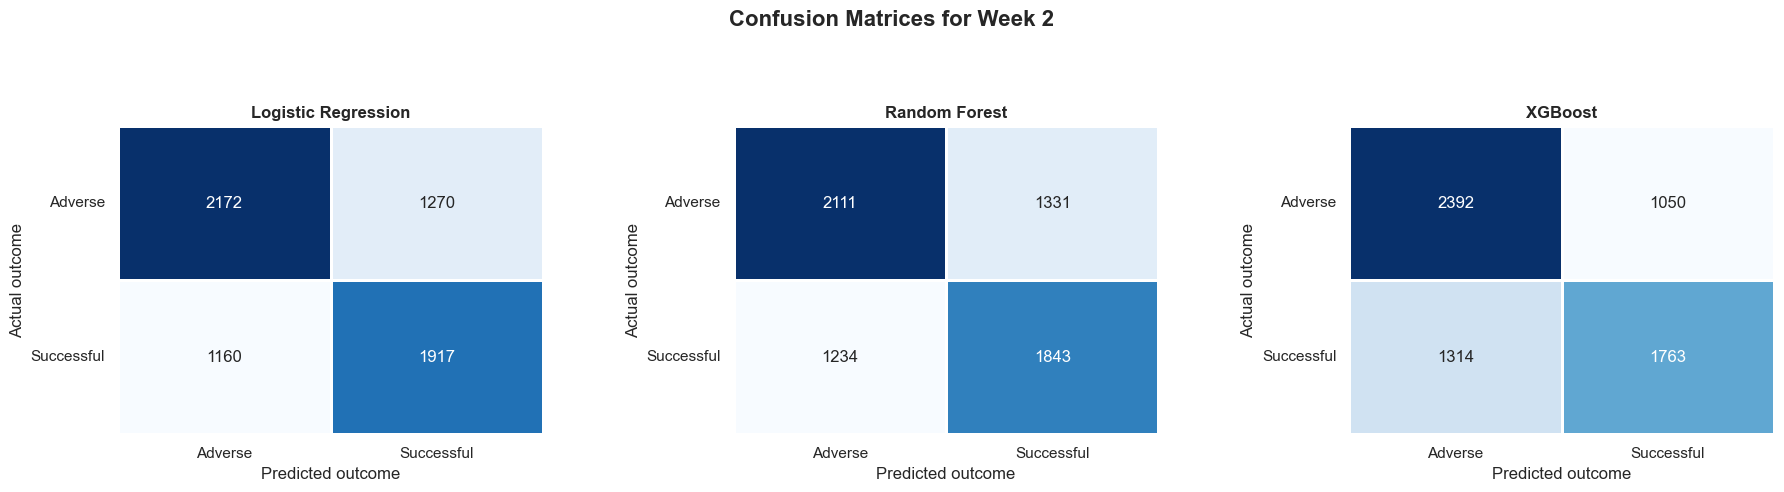

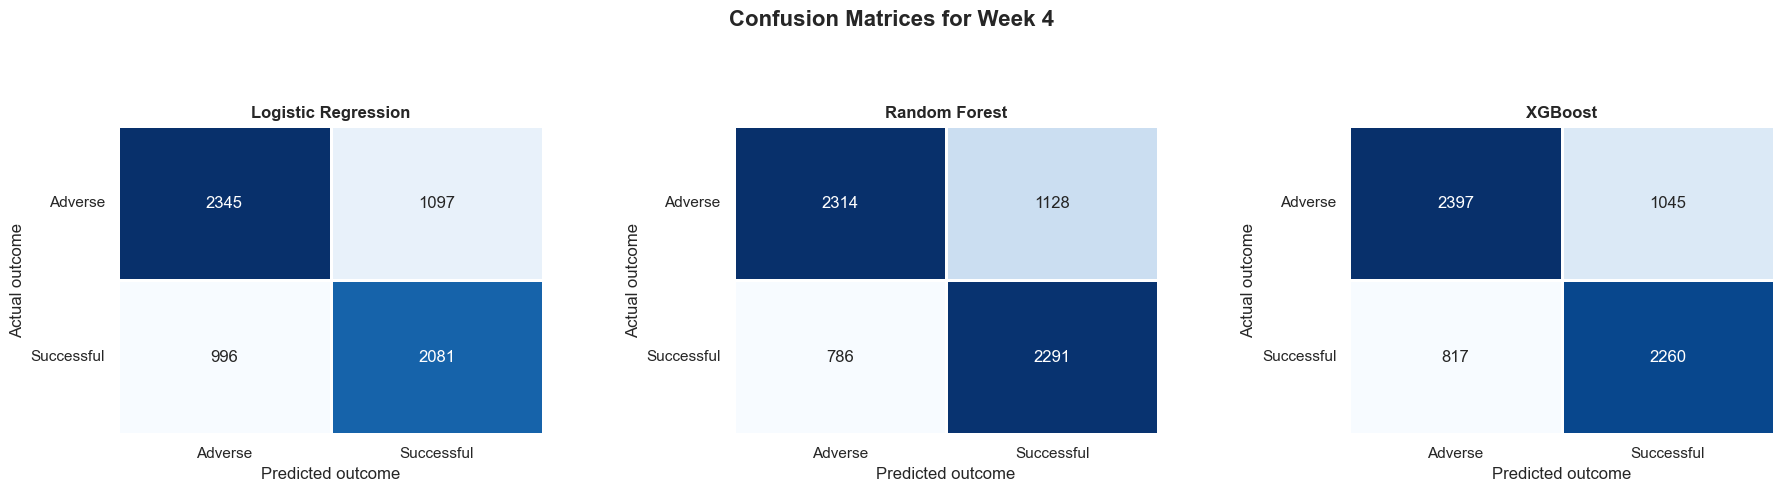

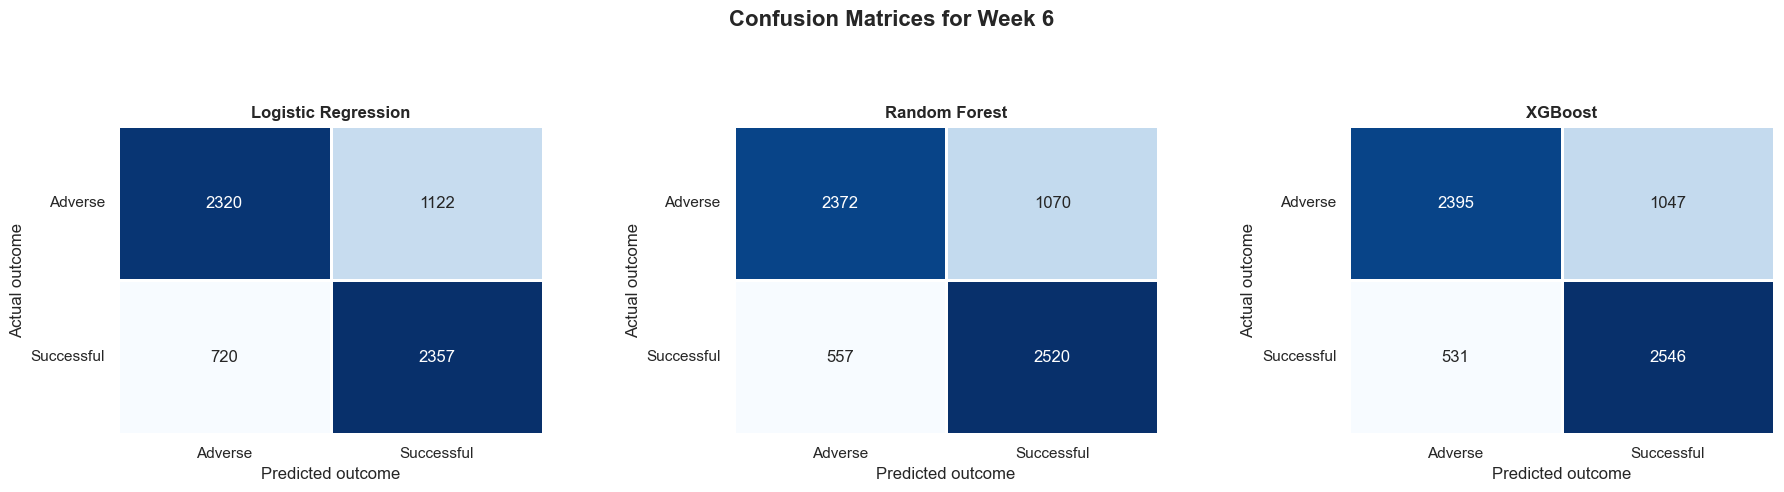

Model performance and confusion matrix results were saved in: c:\Users\pc\OneDrive - ADvTECH Ltd\SEM 2\Research in Programming and Data Analytics\OUALD\oulad_outputs\modelling
Confusion matrix heatmaps were saved in: c:\Users\pc\OneDrive - ADvTECH Ltd\SEM 2\Research in Programming and Data Analytics\OUALD\oulad_outputs\modelling\confusion_matrix_plots


In [14]:
# Display and save the model results

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# Create a copy of the results table
# so that the original results_df remains unchanged
results_display = results_df.copy()


# Convert model performance metrics from decimals to percentages
# For example, 0.7579 becomes 75.79
percentage_columns = [
    column
    for column in results_display.columns
    if column not in ["window", "model"]
]

results_display[percentage_columns] = (
    results_display[percentage_columns] * 100
).round(2)


# Display the model performance results
display(results_display)


# Create a folder for the confusion matrix images
confusion_plot_folder = (
    modelling_folder / "confusion_matrix_plots"
)

confusion_plot_folder.mkdir(
    parents=True,
    exist_ok=True
)


# Create separate confusion matrix heatmaps
# for Week 2, Week 4, and Week 6
for window in ["Week 2", "Week 4", "Week 6"]:

    # Select the results for the current prediction window
    window_data = confusion_df[
        confusion_df["window"] == window
    ]

    # Create three separate heatmaps in one figure
    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(18, 5)
    )

    # Make sure axes can be used consistently
    axes = np.atleast_1d(axes)

    fig.suptitle(
        f"Confusion Matrices for {window}",
        fontsize=16,
        fontweight="bold"
    )

    # Create one heatmap for each model
    for ax, (_, row) in zip(
        axes,
        window_data.iterrows()
    ):

        # Arrange the values into a two-by-two confusion matrix
        confusion_matrix = np.array([
            [
                row["true_adverse_predicted_adverse"],
                row["true_adverse_predicted_successful"]
            ],
            [
                row["true_successful_predicted_adverse"],
                row["true_successful_predicted_successful"]
            ]
        ])

        # Display the confusion matrix as a heatmap
        sns.heatmap(
            confusion_matrix,
            annot=True,
            fmt=".0f",
            cmap="Blues",
            cbar=False,
            linewidths=1,
            linecolor="white",
            ax=ax
        )

        # Add the model name
        ax.set_title(
            row["model"],
            fontsize=12,
            fontweight="bold"
        )

        # Add axis labels
        ax.set_xlabel("Predicted outcome")
        ax.set_ylabel("Actual outcome")

        # Add outcome labels
        ax.set_xticklabels(
            ["Adverse", "Successful"],
            rotation=0
        )

        ax.set_yticklabels(
            ["Adverse", "Successful"],
            rotation=0
        )

    # Add space between the heatmaps
    plt.tight_layout(
        rect=[0, 0, 1, 0.90]
    )

    plt.subplots_adjust(
        wspace=0.45
    )

    # Save the heatmaps as an image
    image_name = (
        window.lower().replace(" ", "_")
        + "_confusion_matrices.png"
    )

    fig.savefig(
        confusion_plot_folder / image_name,
        dpi=300,
        bbox_inches="tight"
    )

    # Display the heatmaps in the notebook
    plt.show()

    # Close the figure after displaying and saving it
    plt.close(fig)


# Save the original model performance results
# These values remain in decimal form
results_df.to_csv(
    modelling_folder / "model_performance_all_windows.csv",
    index=False
)


# Save the confusion matrix values
confusion_df.to_csv(
    modelling_folder / "confusion_matrices_all_windows.csv",
    index=False
)


print(
    "Model performance and confusion matrix results were saved in:",
    modelling_folder
)

print(
    "Confusion matrix heatmaps were saved in:",
    confusion_plot_folder
)



### Results of the different models

All three algorithms performed better than the majority class baseline of 52.8%.

Performance improved as more information became available. XGBoost was the strongest overall model at each prediction window.

At Week 2, XGBoost achieved 63.74% accuracy, 69.49% adverse outcome recall, 66.93% adverse outcome F1 score and 68.32% ROC AUC.

At Week 4, XGBoost achieved 71.44% accuracy, 69.64% adverse outcome recall, 72.03% adverse outcome F1 score and 79.10% ROC AUC.

At Week 6, XGBoost achieved 75.79% accuracy, 69.58% adverse outcome recall, 75.22% adverse outcome F1 score and 84.16% ROC AUC.

These results show that later prediction windows improve the overall classification of students. However, adverse outcome recall remains close to 70% across all three windows. This means that the additional information available at Weeks 4 and 6 improves overall accuracy, but does not greatly increase the proportion of adverse outcome students identified.


### Confusion Matrix

A confusion matrix is a table used to compare the actual outcome of each student with the outcome predicted by the model. Each cell shows the number of students who fall into a particular combination of actual and predicted outcomes. The rows represent the actual outcomes, while the columns represent the predicted outcomes (scikit-learn, n.d.).

In this study, the confusion matrices contain two actual outcomes, adverse and successful. The diagonal cells show correct predictions, while the off-diagonal cells show incorrect predictions. A higher number in the diagonal cells generally indicates more correct classifications (scikit-learn, n.d.).

Interpretation of the Week 2 results
At Week 2, XGBoost correctly identified 2,392 adverse cases and missed 1,050 adverse cases. It also correctly identified 1,763 successful cases, while incorrectly classifying 1,314 successful students as adverse.
Logistic Regression correctly identified 2,172 adverse cases, while Random Forest correctly identified 2,111. Therefore, XGBoost identified the largest number of adverse cases at the Week 2 prediction point.
This agrees with the adverse recall results. XGBoost achieved an adverse recall of 69.5%, compared with 63.1% for Logistic Regression and 61.3% for Random Forest.

Interpretation of the Week 4 results
At Week 4, XGBoost correctly identified 2,397 adverse cases and missed 1,045 adverse cases. This was the highest number of correctly identified adverse cases among the three models at this prediction point.
Logistic Regression correctly identified 2,345 adverse cases, while Random Forest correctly identified 2,314. XGBoost also produced fewer missed adverse cases than both Logistic Regression and Random Forest.
The adverse recall results were 68.1% for Logistic Regression, 67.2% for Random Forest, and 69.6% for XGBoost. This shows that XGBoost continued to provide the strongest detection of adverse outcomes.

Interpretation of the Week 6 results
At Week 6, XGBoost correctly identified 2,395 adverse cases and missed 1,047 adverse cases. Random Forest correctly identified 2,372 adverse cases, while Logistic Regression correctly identified 2,320.
XGBoost also correctly identified 2,546 successful cases and produced 531 false alerts. This was the lowest number of false alerts among the three models at Week 6.
The adverse recall values were 67.4% for Logistic Regression, 68.9% for Random Forest, and 69.6% for XGBoost. Therefore, XGBoost remained the most consistent model for detecting adverse outcomes.

Overall, the confusion matrices indicate that XGBoost provided the most consistent classification performance across the three prediction windows. It identified the highest or near-highest number of adverse cases and maintained the strongest adverse recall. The matrices support the model comparison and prediction-window analysis, but they do not identify which individual variables were the most important predictors. Feature importance analysis is required to address that part of the research.

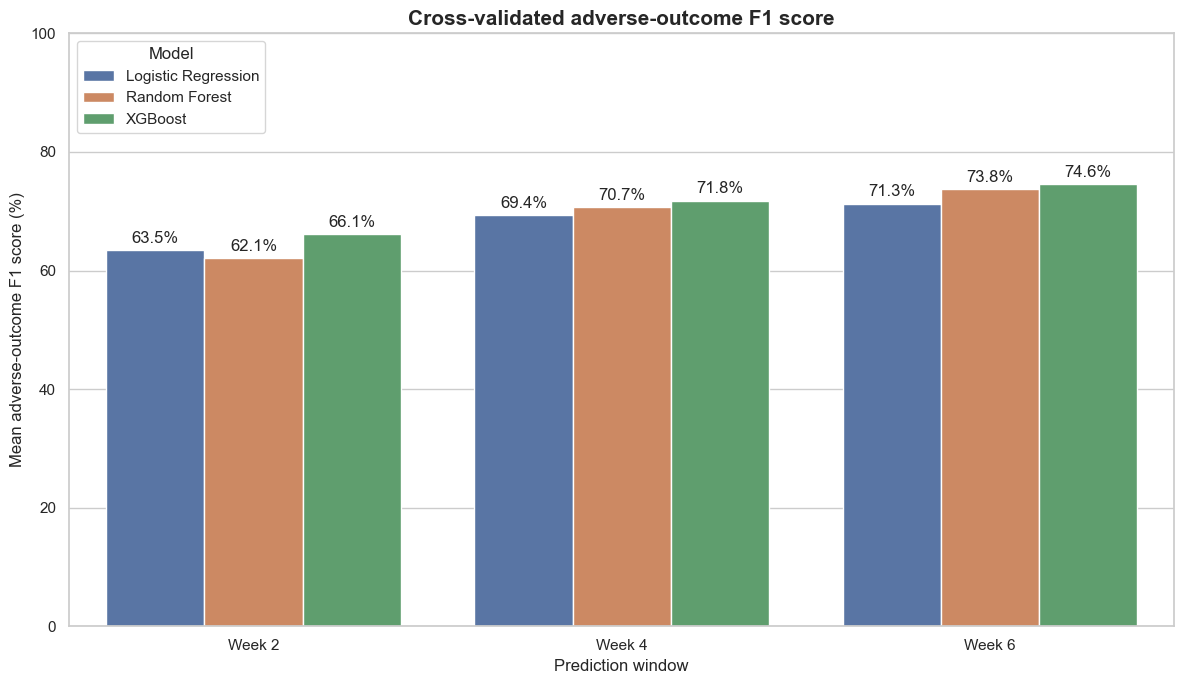

In [15]:
# Create a copy of the results data for plotting
plot_data = results_df.copy()


# Convert the cross-validated adverse F1 score
# from a decimal into a percentage
plot_data["cv_adverse_f1_mean"] = (
    plot_data["cv_adverse_f1_mean"] * 100
).round(2)


# Create the chart
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=plot_data,
    x="window",
    y="cv_adverse_f1_mean",
    hue="model",
    ci=None
)


# Add chart title and axis labels
plt.title(
    "Cross-validated adverse-outcome F1 score",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Prediction window")
plt.ylabel("Mean adverse-outcome F1 score (%)")


# Set the vertical axis from 0% to 100%
plt.ylim(0, 100)


# Add the percentage value above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )


# Position the legend clearly
plt.legend(
    title="Model",
    loc="upper left"
)


# Improve the spacing
plt.tight_layout()


# Save the chart
plt.savefig(
    modelling_folder / "adverse_outcome_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


# Display the chart
plt.show()



The chart shows that adverse-outcome F1 performance improved from Week 2 to Week 6 for all three models.
At Week 2, XGBoost performed best with an F1 score of 66.1%, followed by Logistic Regression at 63.5% and Random Forest at 62.1%. This means XGBoost provided the strongest balance between identifying adverse cases and avoiding incorrect adverse classifications at the earliest prediction point.

At Week 4, performance improved for all models. XGBoost remained the strongest model at 71.8%, followed by Random Forest at 70.7% and Logistic Regression at 69.4%.
At Week 6, XGBoost again achieved the highest score at 74.6%. Random Forest followed at 73.8%, while Logistic Regression recorded 71.3%.

Overall, XGBoost produced the highest cross-validated adverse-outcome F1 score at every prediction window. Its performance increased from 66.1% at Week 2 to 74.6% at Week 6, an improvement of 8.5 percentage points. Random Forest showed the largest improvement, increasing from 62.1% to 73.8%, an increase of 11.7 percentage points.



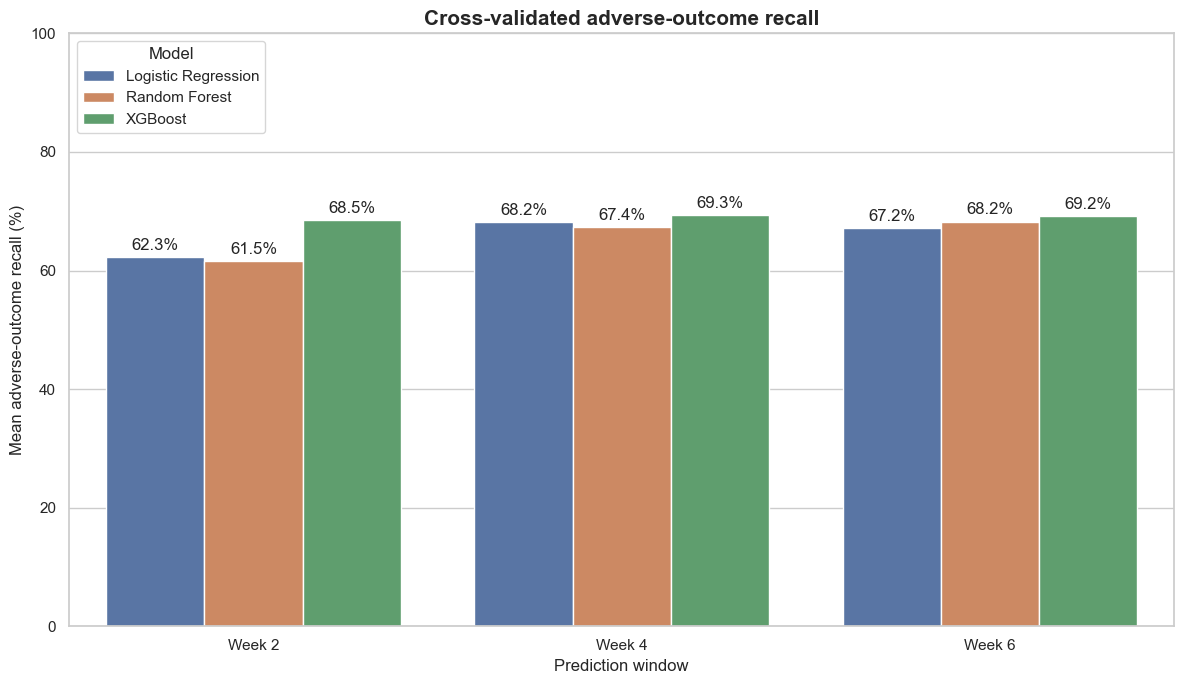

In [16]:
# Create a comparison chart for adverse-outcome recall

import matplotlib.pyplot as plt
import seaborn as sns


# Create a copy so that results_df remains unchanged
recall_plot_data = results_df.copy()


# Convert recall values from decimals to percentages
# For example, 0.685 becomes 68.5
recall_plot_data["cv_adverse_recall_mean"] = (
    recall_plot_data["cv_adverse_recall_mean"] * 100
).round(2)


# Create the bar chart
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=recall_plot_data,
    x="window",
    y="cv_adverse_recall_mean",
    hue="model",
    ci=None
)


# Add the title and axis labels
plt.title(
    "Cross-validated adverse-outcome recall",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Prediction window")
plt.ylabel("Mean adverse-outcome recall (%)")


# Set the vertical axis from 0% to 100%
plt.ylim(0, 100)


# Add the percentage value above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )


# Display the legend
plt.legend(
    title="Model",
    loc="upper left"
)


# Improve the layout
plt.tight_layout()


# Save the chart
plt.savefig(
    modelling_folder / "adverse_outcome_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


# Display the chart
plt.show()


This chart shows the percentage of students with an actual adverse outcome that each model correctly identified during cross-validation. This is called adverse-outcome recall (scikit-learn, n.d.). 
- Week 2: XGBoost identified 68.5% of adverse cases, compared with 62.3% for Logistic Regression and 61.5% for Random Forest.

- Week 4: XGBoost remained highest at 69.3%. Logistic Regression reached 68.2%, and Random Forest reached 67.4%.

- Week 6: XGBoost again performed best at 69.2%, followed by Random Forest at 68.2% and Logistic Regression at 67.2%.

The main finding is that XGBoost was the strongest model at every prediction window. However, its recall changed very little after Week 2. At Week 6, XGBoost still missed approximately 31% of adverse cases, so the model is useful but not perfect.
This suggests that Week 2 may already provide a useful early prediction point, because later data produced only a small improvement in XGBoost recall.

## Feature importance review

Feature importance is reviewed after model training to support RQ3. For Logistic Regression, the absolute coefficient size is used as an indication of contribution within the fitted model. For Random Forest and XGBoost, the model feature importance values are extracted. These values describe how the fitted model used the predictors, but they should not be interpreted as proof of causation.


In [ ]:


# Extract feature importance from each fitted model

importance_rows = []

for (window, model_name), (pipeline, predictor_columns) in fitted_pipelines.items():

    preprocessor = pipeline.named_steps["preprocessor"]
    fitted_model = pipeline.named_steps["model"]

    try:
        feature_names = preprocessor.get_feature_names_out()
    except AttributeError:
        feature_names = np.array(predictor_columns)

    if hasattr(fitted_model, "coef_"):
        importance_values = np.abs(
            fitted_model.coef_[0]
        )
    elif hasattr(fitted_model, "feature_importances_"):
        importance_values = fitted_model.feature_importances_
    else:
        continue

    for feature_name, importance_value in zip(
        feature_names,
        importance_values
    ):
        importance_rows.append({
            "window": f"Week {window}",
            "model": model_name,
            "feature": feature_name,
            "importance": importance_value
        })

importance_df = pd.DataFrame(importance_rows)

if not importance_df.empty:
    importance_df = importance_df.sort_values(
        ["window", "model", "importance"],
        ascending=[True, True, False]
    )

    display(importance_df.groupby(
        ["window", "model"],
        as_index=False
    ).head(15))

    importance_df.to_csv(
        modelling_folder / "feature_importance_all_windows.csv",
        index=False
    )

    print(
        "Feature importance results were saved in:",
        modelling_folder
    )
else:
    print("Feature importance could not be extracted.")


,window,model,feature,importance
5,Week 2,Logistic Regression,numeric__scored_assessment_count,0.824775
9,Week 2,Logistic Regression,numeric__avg_TMA_score,0.610530
4,Week 2,Logistic Regression,numeric__assessment_record_count,0.562143
7,Week 2,Logistic Regression,numeric__assessment_submission_rate,0.492451
12,Week 2,Logistic Regression,numeric__missingindicator_assessment_score_mean,0.413849
...,...,...,...,...
427,Week 6,XGBoost,categorical__gender_M,0.012032
421,Week 6,XGBoost,numeric__num_of_prev_attempts,0.011612
426,Week 6,XGBoost,categorical__gender_F,0.010255
446,Week 6,XGBoost,categorical__imd_band_0-10%,0.009987


Feature importance results were saved in: c:\Users\pc\OneDrive - ADvTECH Ltd\SEM 2\Research in Programming and Data Analytics\OUALD\oulad_outputs\modelling


The feature-importance results indicate that assessment engagement and performance variables were important predictors of adverse outcomes, particularly in the Week 2 Logistic Regression model. The highest visible importance score was associated with the number of scored assessments, followed by the average TMA score, the number of assessment records, and the assessment submission rate.
These results suggest that students’ early assessment activity and performance provided useful information for predicting later outcomes. In contrast, the lower-ranked XGBoost features shown for Week 6, including gender, previous attempts, IMD band, and active days, made smaller contributions to that model’s predictions.
The results support RQ3 by identifying the variables that the models relied on most when predicting adverse outcomes. However, feature importance should be interpreted as model behaviour rather than proof that a predictor directly causes an adverse outcome.

## References

James, G., Witten, D., Hastie, T., Tibshirani, R. and Taylor, J. 2023. *An introduction to statistical learning: With applications in Python*. 1st ed. Cham: Springer. [Online]. Available at: https://doi.org/10.1007/978-3-031-38747-0 [Accessed 26 August 2026].

Kuzilek, J., Hlosta, M. and Zdráhal, Z. 2017. ‘Open University Learning Analytics dataset’. *Scientific Data*, 4(1), article 170171. [Online]. Available at: https://doi.org/10.1038/sdata.2017.171 [Accessed 26 August 2026].

Ozdemir, S. 2016. *Principles of data science*. 1st ed. Packt Publishing. [Online]. Available at: https://www.packtpub.com/en-us/product/principles-of-data-science-9781785887918 [Accessed 26 August 2026].

scikit learn  n.d. *User guide*. [Online]. Available at: https://scikit-learn.org/stable/user_guide.html [Accessed 26 August 2026].

XGBoost  n.d. *XGBoost documentation*. [Online]. Available at: https://xgboost.readthedocs.io/en/stable/ [Accessed 26 August 2026].
